# Exercise 1 - Compute and validate linear growth

Reference: Lecture 5 notes, Sections 3.4-3.7. Code: `Library/exercise_1.py`.

In [1]:
%matplotlib widget
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("../Library")   # folder with the exercise modules

import numpy as np
import matplotlib.pyplot as plt

import exercise_1 as ex1

## (a) Growing-mode equation in $N = \ln a$

$$G_{NN} + \left(2 + \frac{d\ln H}{dN}\right) G_N - \frac{3}{2}\Omega_m(a) G = 0, \qquad G(a_i) = G_N(a_i) = a_i \quad \text{(eq. 3.24)}$$

Outputs: $D = G/G(1)$ and $f = G_N/G$ (from the ODE state, no numerical derivative).

In [2]:
# Flat LCDM as a first example
Om0, OL0 = 0.3, 0.7   # density parameters today (Ok0 = 1 - Om0 - OL0 = 0)
a_i = 1e-3            # initial scale factor, deep in matter domination

# Log-spaced grid of scale factors from a_i to today
aa = np.logspace(np.log10(a_i), 0, 200)

# Solve the growth ODE: D normalized to D(1) = 1, f = d ln D / d ln a
D, f = ex1.growth_ode(aa, Om0, OL0, a_i=a_i)

print(f"D(a=1) = {D[-1]:.6f}   (normalization D(1) = 1)")
print(f"f(a=1) = {f[-1]:.6f}")
# D/a at a_i: > 1 because Lambda suppresses the growth at late times (D is normalized today)
print(f"D(a_i)/a_i = {D[0]/a_i:.6f}")

D(a=1) = 1.000000   (normalization D(1) = 1)
f(a=1) = 0.512796
D(a_i)/a_i = 1.283728


## (b) EdS check and comparison with flat ΛCDM and open CDM

EdS ($\Omega_{m0} = 1$): $d\ln H/dN = -3/2$, $\Omega_m = 1$, so $G_{NN} + \tfrac12 G_N - \tfrac32 G = 0$ with growing mode $G = a$. Expect $D = a$, $f = 1$. Normalization: $D(1) = 1$.

In [3]:
# Einstein-de Sitter: matter only, at all times
D_EdS, f_EdS = ex1.growth_ode(aa, 1.0, 0.0, a_i=a_i)

# Maximum deviation from the exact solution D = a, f = 1
print(f"max |D - a| = {np.max(np.abs(D_EdS - aa)):.2e}")
print(f"max |f - 1| = {np.max(np.abs(f_EdS - 1)):.2e}")

max |D - a| = 1.47e-11
max |f - 1| = 2.22e-16


In [4]:
# Flat LCDM: Om0 = 0.3, OL0 = 0.7 (Ok0 = 0)
D_LCDM, f_LCDM = ex1.growth_ode(aa, 0.3, 0.7, a_i=a_i)

# Open CDM: Om0 = 0.3, OL0 = 0 (Ok0 = 0.7)
D_OCDM, f_OCDM = ex1.growth_ode(aa, 0.3, 0.0, a_i=a_i)

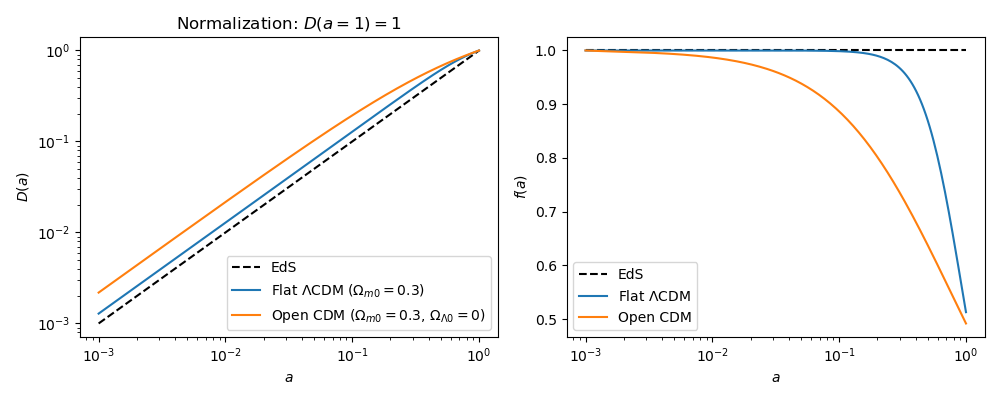

In [5]:
# Plot D(a) and f(a) for the three models, all normalized to D(a=1) = 1
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# Left panel: growth factor (log-log, so EdS is the straight line D = a)
ax[0].loglog(aa, D_EdS, "k--", label="EdS")
ax[0].loglog(aa, D_LCDM, label=r"Flat $\Lambda$CDM ($\Omega_{m0}=0.3$)")
ax[0].loglog(aa, D_OCDM, label=r"Open CDM ($\Omega_{m0}=0.3$, $\Omega_{\Lambda0}=0$)")
ax[0].set_xlabel("$a$")
ax[0].set_ylabel("$D(a)$")
ax[0].set_title("Normalization: $D(a=1) = 1$")
ax[0].legend()

# Right panel: growth rate (EdS is the constant f = 1)
ax[1].semilogx(aa, f_EdS, "k--", label="EdS")
ax[1].semilogx(aa, f_LCDM, label=r"Flat $\Lambda$CDM")
ax[1].semilogx(aa, f_OCDM, label="Open CDM")
ax[1].set_xlabel("$a$")
ax[1].set_ylabel("$f(a)$")
ax[1].legend()

plt.tight_layout()
plt.show()

## (c) ODE vs independent quadrature

$$G(a) = \frac{5 \Omega_{m0}}{2} E(a) \int_0^a \frac{d\tilde{a}}{\tilde{a}^3 E^3(\tilde{a})} \quad \text{(eq. 3.33)}$$

Exact for matter + curvature + Λ, and independent of $a_i$ and of the ODE solver. We compare $D = G/G(1)$, since the two $G$ may differ by a constant factor.

In [6]:
# Quadrature result for the same models and the same grid aa as in (b)
D_EdS_q = ex1.growth_quad(aa, 1.0, 0.0)
D_LCDM_q = ex1.growth_quad(aa, 0.3, 0.7)
D_OCDM_q = ex1.growth_quad(aa, 0.3, 0.0)

# Relative difference |D_ODE - D_quad| / D_quad over [a_i, 1], and where it is largest
for name, D_ode, D_q in [("EdS", D_EdS, D_EdS_q),
                         ("Flat LCDM", D_LCDM, D_LCDM_q),
                         ("Open CDM", D_OCDM, D_OCDM_q)]:
    rel_diff = np.abs(D_ode - D_q) / D_q
    print(f"{name:10s}: max rel. diff = {rel_diff.max():.2e} at a = {aa[rel_diff.argmax()]:.2e}")

EdS       : max rel. diff = 3.40e-10 at a = 1.00e-03
Flat LCDM : max rel. diff = 8.36e-10 at a = 1.00e-03
Open CDM  : max rel. diff = 5.33e-04 at a = 1.00e-03


## (d) Sensitivity to $a_i$ and to the solver tolerances

- **Initial-mode error**: $G = G_N = a_i$ is exact only in EdS; otherwise a decaying mode $\propto a^{-5/2}$ is excited (eq. 3.12). Depends on $a_i$.
- **Solver error**: RK45 truncation, set by `rtol`.

We vary one at a time against a reference ($a_i = 10^{-6}$, `rtol` $= 10^{-12}$), on a common grid $a \in [10^{-2}, 1]$.

In [7]:
# Common grid for all runs (starts at the largest a_i we test)
a_d = np.logspace(-2, 0, 100)

# Non-EdS models of (b): (Om0, OL0)
models = {"Flat LCDM": (0.3, 0.7), "Open CDM": (0.3, 0.0)}

# Reference solutions: very early start and very tight tolerance.
# atol = 0, so rtol alone sets the step size (G > 0, so a pure relative tolerance is well defined)
a_i_ref, rtol_ref = 1e-6, 1e-12
ref = {}
for name, (Om0, OL0) in models.items():
    ref[name] = ex1.growth_ode(a_d, Om0, OL0, a_i=a_i_ref, rtol=rtol_ref, atol=0.0)

    # Validate the reference D against the quadrature of (c)
    D_q = ex1.growth_quad(a_d, Om0, OL0)
    print(f"{name:10s}: reference vs quadrature, max rel. diff in D = {np.max(np.abs(ref[name][0] / D_q - 1)):.1e}")

Flat LCDM : reference vs quadrature, max rel. diff in D = 7.3e-13
Open CDM  : reference vs quadrature, max rel. diff in D = 5.9e-13


In [8]:
# Vary a_i at fixed (tight) tolerance -> isolates the initial-mode error
for name, (Om0, OL0) in models.items():
    D_ref, f_ref = ref[name]
    print(name)
    for a_i_test in [1e-2, 1e-3, 1e-4, 1e-5]:
        D_t, f_t = ex1.growth_ode(a_d, Om0, OL0, a_i=a_i_test, rtol=rtol_ref, atol=0.0)
        # Maximum relative change with respect to the reference, over the whole grid
        dD = np.max(np.abs(D_t / D_ref - 1))
        df = np.max(np.abs(f_t / f_ref - 1))
        print(f"  a_i = {a_i_test:.0e}:  max |dD/D| = {dD:.1e},  max |df/f| = {df:.1e}")

Flat LCDM
  a_i = 1e-02:  max |dD/D| = 5.1e-07,  max |df/f| = 1.3e-06
  a_i = 1e-03:  max |dD/D| = 1.7e-12,  max |df/f| = 4.0e-12
  a_i = 1e-04:  max |dD/D| = 2.7e-13,  max |df/f| = 1.4e-12
  a_i = 1e-05:  max |dD/D| = 1.3e-13,  max |df/f| = 7.2e-13
Open CDM
  a_i = 1e-02:  max |dD/D| = 5.3e-03,  max |df/f| = 1.3e-02
  a_i = 1e-03:  max |dD/D| = 1.7e-06,  max |df/f| = 4.3e-06
  a_i = 1e-04:  max |dD/D| = 5.5e-10,  max |df/f| = 1.4e-09


  a_i = 1e-05:  max |dD/D| = 1.6e-13,  max |df/f| = 4.4e-13


In [9]:
# Vary rtol at fixed (very early) a_i -> isolates the solver error
for name, (Om0, OL0) in models.items():
    D_ref, f_ref = ref[name]
    print(name)
    for rtol_test in [1e-3, 1e-5, 1e-7, 1e-9]:
        D_t, f_t = ex1.growth_ode(a_d, Om0, OL0, a_i=a_i_ref, rtol=rtol_test, atol=0.0)
        # Maximum relative change with respect to the reference, over the whole grid
        dD = np.max(np.abs(D_t / D_ref - 1))
        df = np.max(np.abs(f_t / f_ref - 1))
        print(f"  rtol = {rtol_test:.0e}:  max |dD/D| = {dD:.1e},  max |df/f| = {df:.1e}")

Flat LCDM
  rtol = 1e-03:  max |dD/D| = 8.2e-04,  max |df/f| = 1.4e-03
  rtol = 1e-05:  max |dD/D| = 7.0e-06,  max |df/f| = 1.6e-05
  rtol = 1e-07:  max |dD/D| = 7.6e-08,  max |df/f| = 1.7e-07
  rtol = 1e-09:  max |dD/D| = 7.5e-10,  max |df/f| = 1.5e-09
Open CDM
  rtol = 1e-03:  max |dD/D| = 1.1e-03,  max |df/f| = 1.3e-03
  rtol = 1e-05:  max |dD/D| = 4.6e-06,  max |df/f| = 4.7e-06
  rtol = 1e-07:  max |dD/D| = 5.1e-08,  max |df/f| = 4.0e-08


  rtol = 1e-09:  max |dD/D| = 5.6e-10,  max |df/f| = 4.1e-10


### Discussion

- **Solver error** $\sim$ `rtol`, the same for both models.
- **Initial-mode error** is model dependent. Open CDM: curvature perturbs $E^2$ by $\sim(\Omega_{k0}/\Omega_{m0})\,a_i$, and the excited decaying mode drops by $\sim 10^{3.5}$ per decade in $a_i$. Flat ΛCDM: the correction is $\sim(\Omega_{\Lambda0}/\Omega_{m0})\,a_i^3$, negligible for $a_i \le 10^{-3}$.
- $f$ is $\approx 2.5\times$ more sensitive than $D$ to this error: for a decaying fraction $\epsilon \propto a^{-5/2}$, $\delta f \approx d\epsilon/dN = -\tfrac52\epsilon$.
- Defaults ($a_i = 10^{-3}$, `rtol` $= 10^{-10}$): errors $\lesssim 10^{-5}$ for $a \ge 10^{-2}$; near $a_i$, open CDM still has $\sim 5\times10^{-4}$, as seen in (c).